# Python Assignment 20 :RNN

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv("monthly_milk_production.csv")
df

,Date,Production
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


In [3]:
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)


In [4]:
df.head()

,Production
Date,
1962-01-01,589
1962-02-01,561
1962-03-01,640
1962-04-01,656
1962-05-01,727


In [5]:
df['Month'] = df.index.month


In [6]:
print(df.isnull().sum())


Production    0
Month         0
dtype: int64


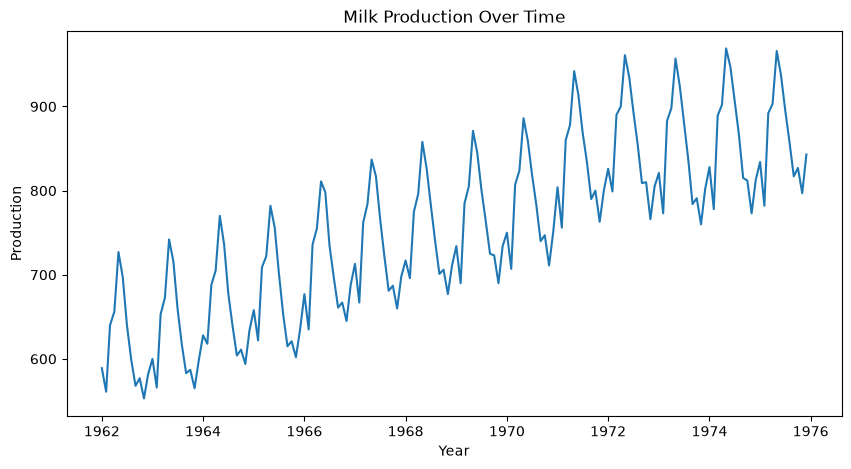

In [7]:
plt.figure(figsize=(10,5))
plt.plot(df['Production'])
plt.title("Milk Production Over Time")
plt.xlabel("Year")
plt.ylabel("Production")
plt.show()


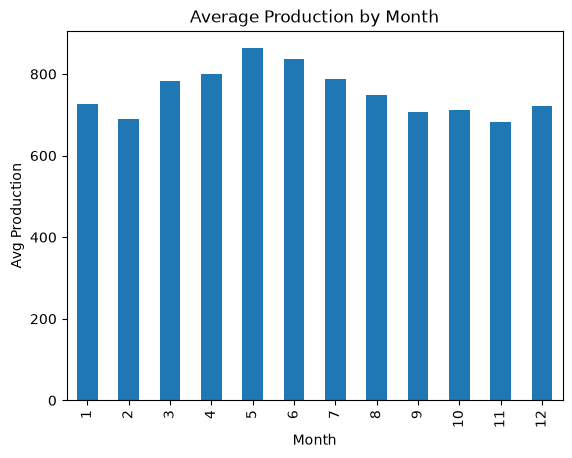

In [8]:
df['Month'] = df.index.month

monthly_avg = df.groupby('Month')['Production'].mean()

monthly_avg.plot(kind='bar', title="Average Production by Month")
plt.xlabel("Month")
plt.ylabel("Avg Production")
plt.show()


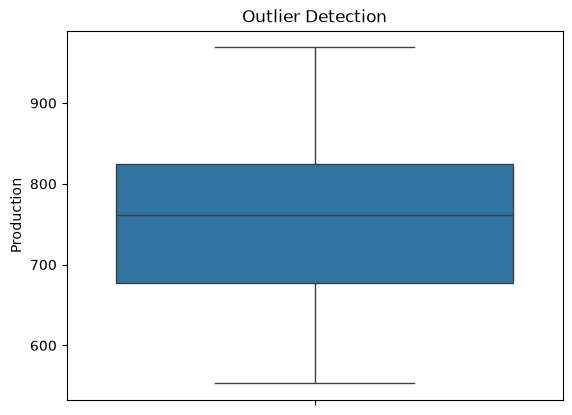

In [9]:
sns.boxplot(df['Production'])
plt.title("Outlier Detection")
plt.show()


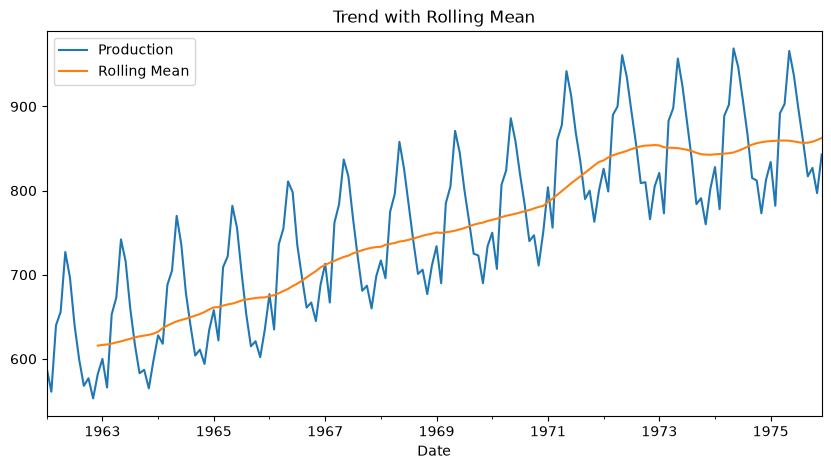

In [10]:
df['Rolling Mean'] = df['Production'].rolling(window=12).mean()

df[['Production', 'Rolling Mean']].plot(figsize=(10,5))
plt.title("Trend with Rolling Mean")
plt.show()


In [11]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df['Scaled'] = scaler.fit_transform(df[['Production']])


In [12]:
from sklearn.preprocessing import MinMaxScaler

# Use only production column
data = df[['Production']].values

# Scale data
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Function to create sequences
def create_sequences(data, seq_length=12):
    X, y = [], []

    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])   # past 12 months
        y.append(data[i+seq_length])     # next month

    return np.array(X), np.array(y)

# Create sequences
X, y = create_sequences(scaled_data, 12)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (156, 12, 1)
y shape: (156, 1)


In [13]:
train_size = int(len(X) * 0.7)
val_size = int(len(X) * 0.15)

X_train = X[:train_size]
y_train = y[:train_size]

X_val = X[train_size:train_size+val_size]
y_val = y[train_size:train_size+val_size]

X_test = X[train_size+val_size:]
y_test = y[train_size+val_size:]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (109, 12, 1)
Validation: (23, 12, 1)
Test: (24, 12, 1)


In [14]:
X_train.shape

(109, 12, 1)

In [15]:
import sys
!{sys.executable} -m pip install tensorflow

'C:\Users\MD' is not recognized as an internal or external command,
operable program or batch file.


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense


In [17]:
rnn_model = Sequential()

rnn_model.add(SimpleRNN(50, activation='relu', input_shape=(X_train.shape[1], 1)))
rnn_model.add(Dense(1))

rnn_model.compile(optimizer='adam', loss='mse')

history_rnn = rnn_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    validation_data=(X_val, y_val)
)


C:\Users\MD SOHAIL\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - loss: 0.0858 - val_loss: 0.1077
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0316 - val_loss: 0.0206
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0203 - val_loss: 0.0218
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0163 - val_loss: 0.0182
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0145 - val_loss: 0.0216
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0141 - val_loss: 0.0175
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0124 - val_loss: 0.0134
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0112 - val_loss: 0.0113
Epoch 9/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0104 - val_loss: 0.0110
Epoch 10/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0096 - val_loss: 0.0090
Epoch 11/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0087 - val_loss: 0.0085
Epoch 12/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0079 - val_loss: 0.0070


In [18]:
lstm_model = Sequential()

lstm_model.add(LSTM(50, activation='relu', input_shape=(X_train.shape[1], 1)))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer='adam', loss='mse')

history_lstm = lstm_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    validation_data=(X_val, y_val)
)


Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 178ms/step - loss: 0.2339 - val_loss: 0.5124
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1793 - val_loss: 0.3869
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1307 - val_loss: 0.2653
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0817 - val_loss: 0.1375
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0379 - val_loss: 0.0330
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0297 - val_loss: 0.0236
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0263 - val_loss: 0.0336
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0240 - val_loss: 0.0357
Epoch 9/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0231 - val_loss: 0.0249
Epoch 10/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0225 - val_loss: 0.0223
Epoch 11/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0216 - val_loss: 0.0242
Epoch 12/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0216 - val_loss: 0.0247


In [19]:
gru_model = Sequential()

gru_model.add(GRU(50, activation='relu', input_shape=(X_train.shape[1], 1)))
gru_model.add(Dense(1))

gru_model.compile(optimizer='adam', loss='mse')

history_gru = gru_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    validation_data=(X_val, y_val)
)


Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 147ms/step - loss: 0.1774 - val_loss: 0.3587
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1143 - val_loss: 0.2360
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0672 - val_loss: 0.1375
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0347 - val_loss: 0.0646
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0238 - val_loss: 0.0283
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0250 - val_loss: 0.0233
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0234 - val_loss: 0.0308
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0218 - val_loss: 0.0407
Epoch 9/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0214 - val_loss: 0.0418
Epoch 10/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0208 - val_loss: 0.0370
Epoch 11/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0204 - val_loss: 0.0315
Epoch 12/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0201 - val_loss: 0.0305


In [20]:
units_list = [32, 50, 100]
batch_sizes = [16, 32]
epochs_list = [20, 30]


In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense

def build_model(model_type, units, input_shape):
    model = Sequential()
    if model_type == "SimpleRNN":
        model.add(SimpleRNN(units, activation='relu', input_shape=input_shape))
    elif model_type == "LSTM":
        model.add(LSTM(units, activation='relu', input_shape=input_shape))
    elif model_type == "GRU":
        model.add(GRU(units, activation='relu', input_shape=input_shape))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse')
    return model

results = []

for units in units_list:
    for batch in batch_sizes:
        for epochs in epochs_list:

            model = build_model("LSTM", units, (X_train.shape[1], 1))

            history = model.fit(
                X_train, y_train,
                epochs=epochs,
                batch_size=batch,
                validation_split=0.2,
                verbose=0
            )

            final_loss = history.history['val_loss'][-1]

            results.append((units, batch, epochs, final_loss))

            print(f"Units: {units}, Batch: {batch}, Epochs: {epochs}, Val Loss: {final_loss}")

Units: 32, Batch: 16, Epochs: 20, Val Loss: 0.017507703974843025
Units: 32, Batch: 16, Epochs: 30, Val Loss: 0.015259173698723316
Units: 32, Batch: 32, Epochs: 20, Val Loss: 0.03264479339122772
Units: 32, Batch: 32, Epochs: 30, Val Loss: 0.04116104915738106
Units: 50, Batch: 16, Epochs: 20, Val Loss: 0.0099082225933671
Units: 50, Batch: 16, Epochs: 30, Val Loss: 0.012417059391736984
Units: 50, Batch: 32, Epochs: 20, Val Loss: 0.025524986907839775
Units: 50, Batch: 32, Epochs: 30, Val Loss: 0.02469191700220108
Units: 100, Batch: 16, Epochs: 20, Val Loss: 0.005956354551017284
Units: 100, Batch: 16, Epochs: 30, Val Loss: 0.007060640957206488
Units: 100, Batch: 32, Epochs: 20, Val Loss: 0.02727801725268364
Units: 100, Batch: 32, Epochs: 30, Val Loss: 0.016975916922092438


In [22]:
best = min(results, key=lambda x: x[3])
print("\nBest Parameters:")
print(f"Units: {best[0]}, Batch: {best[1]}, Epochs: {best[2]}")



Best Parameters:
Units: 100, Batch: 16, Epochs: 20


In [23]:
best_units, best_batch, best_epochs = best[0], best[1], best[2]

final_model = build_model("LSTM", best_units, (X_train.shape[1], 1))

final_model.fit(
    X_train, y_train,
    epochs=best_epochs,
    batch_size=best_batch,
    validation_data=(X_test, y_test)
)


Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 145ms/step - loss: 0.1808 - val_loss: 0.3326
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0854 - val_loss: 0.0962
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0307 - val_loss: 0.0351
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0296 - val_loss: 0.0290
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0236 - val_loss: 0.0383
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0227 - val_loss: 0.0238
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0219 - val_loss: 0.0209
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0215 - val_loss: 0.0250
Epoch 9/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0204 - val_loss: 0.0205
Epoch 10/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0203 - val_loss: 0.0184
Epoch 11/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0187 - val_loss: 0.0210
Epoch 12/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0183 - val_loss: 0.0158


In [24]:
# RNN
rnn_pred = rnn_model.predict(X_test)

# LSTM
lstm_pred = lstm_model.predict(X_test)

# GRU
gru_pred = gru_model.predict(X_test)

# Inverse scaling
rnn_pred = scaler.inverse_transform(rnn_pred)
lstm_pred = scaler.inverse_transform(lstm_pred)
gru_pred = scaler.inverse_transform(gru_pred)

y_test_actual = scaler.inverse_transform(y_test)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step


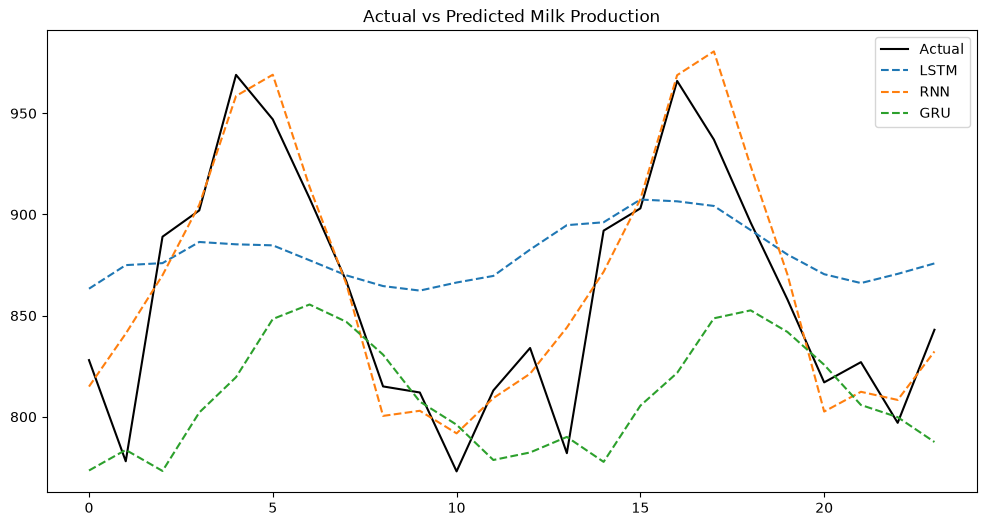

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(y_test_actual, label='Actual', color='black')
plt.plot(lstm_pred, label='LSTM', linestyle='--')
plt.plot(rnn_pred, label='RNN', linestyle='--')
plt.plot(gru_pred, label='GRU', linestyle='--')

plt.title("Actual vs Predicted Milk Production")
plt.legend()
plt.show()


In [26]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return rmse, mae, mape

# RNN
rnn_rmse, rnn_mae, rnn_mape = calculate_metrics(y_test_actual, rnn_pred)

# LSTM
lstm_rmse, lstm_mae, lstm_mape = calculate_metrics(y_test_actual, lstm_pred)

# GRU
gru_rmse, gru_mae, gru_mape = calculate_metrics(y_test_actual, gru_pred)


In [27]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "RMSE": [rnn_rmse, lstm_rmse, gru_rmse],
    "MAE": [rnn_mae, lstm_mae, gru_mae],
    "MAPE": [rnn_mape, lstm_mape, gru_mape]
})

print(results)


  Model       RMSE        MAE      MAPE
0   RNN  23.957516  17.550809  2.087692
1  LSTM  54.362885  44.893570  5.351356
2   GRU  71.673125  55.246735  6.146337


In [28]:
# Number of future steps
future_steps = 12

# Take last sequence from test data
last_sequence = X_test[-1]

future_predictions = []

current_sequence = last_sequence.copy()

for _ in range(future_steps):
    # Reshape for model
    pred = lstm_model.predict(current_sequence.reshape(1, current_sequence.shape[0], 1))

    future_predictions.append(pred[0][0])

    # Update sequence (slide window)
    current_sequence = np.append(current_sequence[1:], pred, axis=0)

# Convert to array
future_predictions = np.array(future_predictions).reshape(-1,1)

# Inverse scaling
future_predictions = scaler.inverse_transform(future_predictions)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


In [30]:
# Last date in dataset
last_date = df.index[-1]

# Generate next 12 months
future_dates = pd.date_range(last_date, periods=13, freq='ME')[1:]


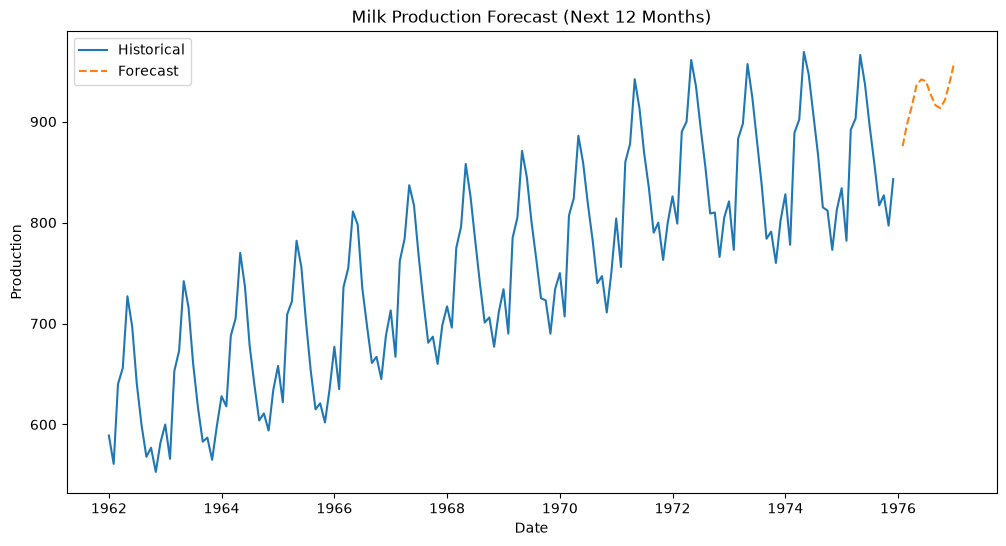

In [31]:
plt.figure(figsize=(12,6))

# Plot historical data
plt.plot(df.index, df['Production'], label='Historical')

# Plot forecast
plt.plot(future_dates, future_predictions, label='Forecast', linestyle='--')

plt.title("Milk Production Forecast (Next 12 Months)")
plt.xlabel("Date")
plt.ylabel("Production")
plt.legend()
plt.show()
